In [1]:
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

def pred_robust(seed: int, p: float, gamma: float, num_node: int, scale: float, T: int, forecast_step: int):
    dir = 'p_' + str(p) + '_gamma_' + str(gamma)
    TICKERS = [str(i) for i in range (num_node)]
    G = nx.erdos_renyi_graph(num_node, p, seed=seed)
    G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
    A = nx.to_numpy_array(G)

    adj_sim = adj_to_line_graph(A, TICKERS)
    adj_L_sim = adjacency_matrices(adj_sim[0], 1)
    W_C_sim = edge_weight(adj_L_sim)
    X_sim = GraphOUEdge([1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, dir, scale=scale, T=T)
    X_sim.alpha_set(np.array([[5]+[1 for _ in range(len(adj_sim[1]) - 1)]]))
    X_sim.beta_set([[2]])
    X_sim.Q_matrix()
    data_sim = X_sim.simulate('CP', 2, seed=1000, rate=1)

    edges = list(G.edges())
    G_without_first = G.copy()
    first_edge = edges[0]
    G_without_first.remove_edge(*first_edge)
    A_without_first = nx.to_numpy_array(G_without_first, nodelist=TICKERS)

    G_without_last = G.copy()
    last_edge = edges[-1]
    G_without_last.remove_edge(*last_edge)
    A_without_last = nx.to_numpy_array(G_without_last, nodelist=TICKERS)

    model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='correct', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_first, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_5', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_last, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_1', scenario=dir)

    boxplot_(data_sim, dir)

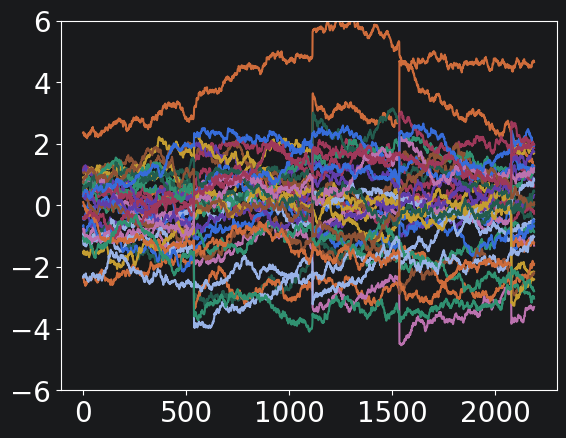

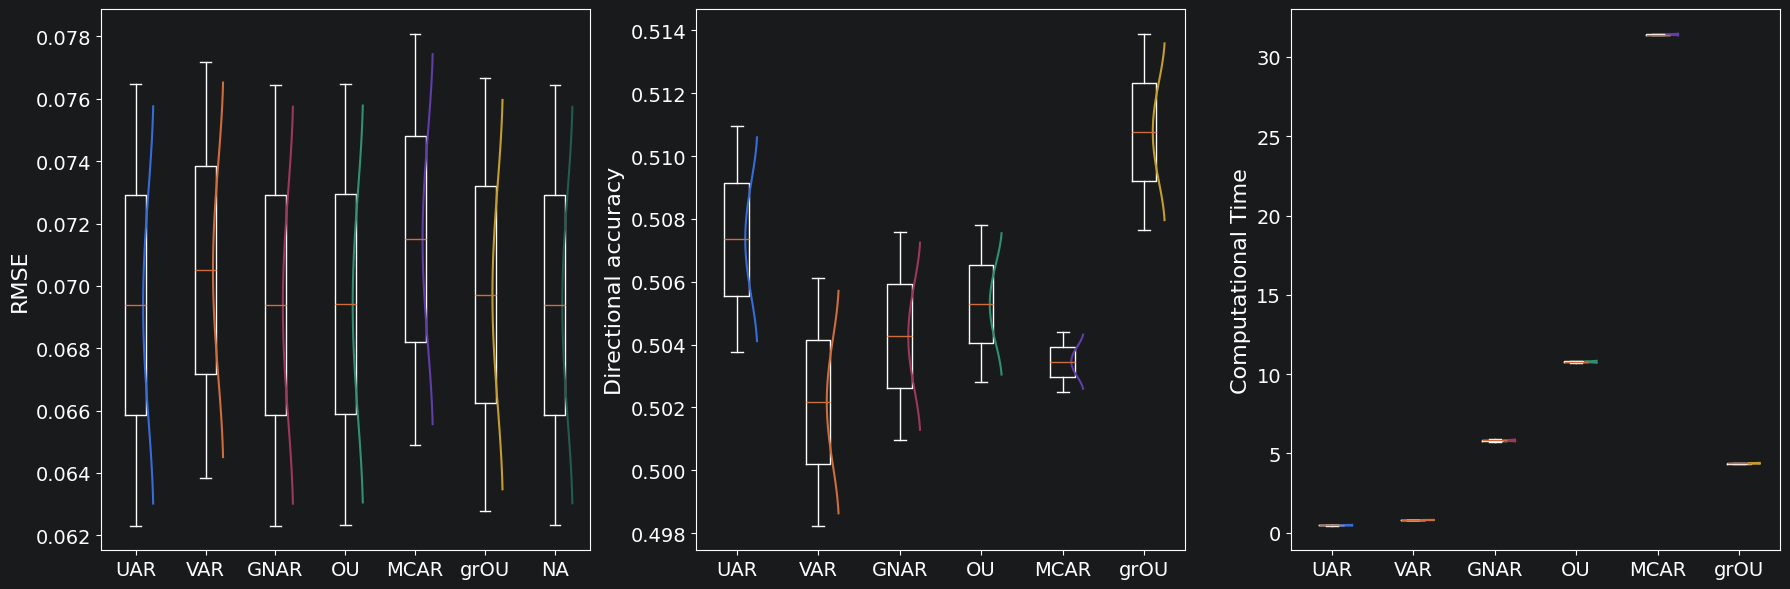

correct
                                UAR       VAR      GNAR         OU       MCAR  \
RMSE_mean                  0.069388  0.070515  0.069379   0.069417   0.071497   
RMSE_std                   0.007080  0.006675  0.007072   0.007074   0.006595   
Directional_accuracy_mean  0.507353  0.502169  0.504265   0.505294   0.503456   
Directional_accuracy_std   0.003603  0.003934  0.003309   0.002500   0.000956   
Computational_time_mean    0.471841  0.801754  5.815995  10.779539  31.415368   
Computational_time_std     0.027462  0.008800  0.064047   0.068437   0.058494   

                               grOU        NA  
RMSE_mean                  0.069719  0.069384  
RMSE_std                   0.006940  0.007066  
Directional_accuracy_mean  0.510772       NaN  
Directional_accuracy_std   0.003125       NaN  
Computational_time_mean    4.375910       NaN  
Computational_time_std     0.031803       NaN  


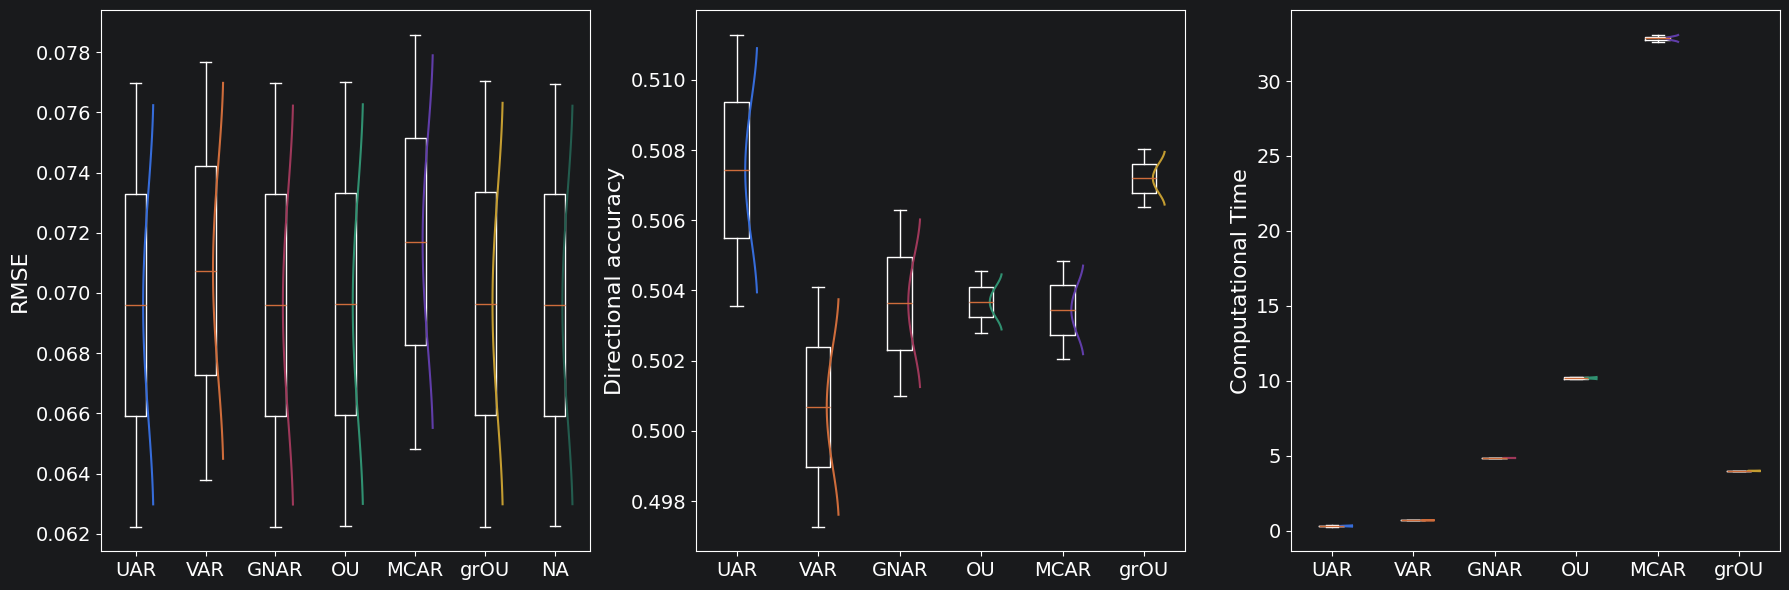

missing_5
                                UAR       VAR      GNAR         OU       MCAR  \
RMSE_mean                  0.069607  0.070735  0.069598   0.069631   0.071706   
RMSE_std                   0.007367  0.006937  0.007361   0.007374   0.006876   
Directional_accuracy_mean  0.507424  0.500682  0.503636   0.503674   0.503447   
Directional_accuracy_std   0.003864  0.003409  0.002652   0.000871   0.001402   
Computational_time_mean    0.317546  0.698567  4.853851  10.185917  32.842663   
Computational_time_std     0.045297  0.004563  0.004953   0.076864   0.254325   

                               grOU        NA  
RMSE_mean                  0.069648  0.069602  
RMSE_std                   0.007408  0.007353  
Directional_accuracy_mean  0.507197       NaN  
Directional_accuracy_std   0.000833       NaN  
Computational_time_mean    3.994040       NaN  
Computational_time_std     0.020319       NaN  


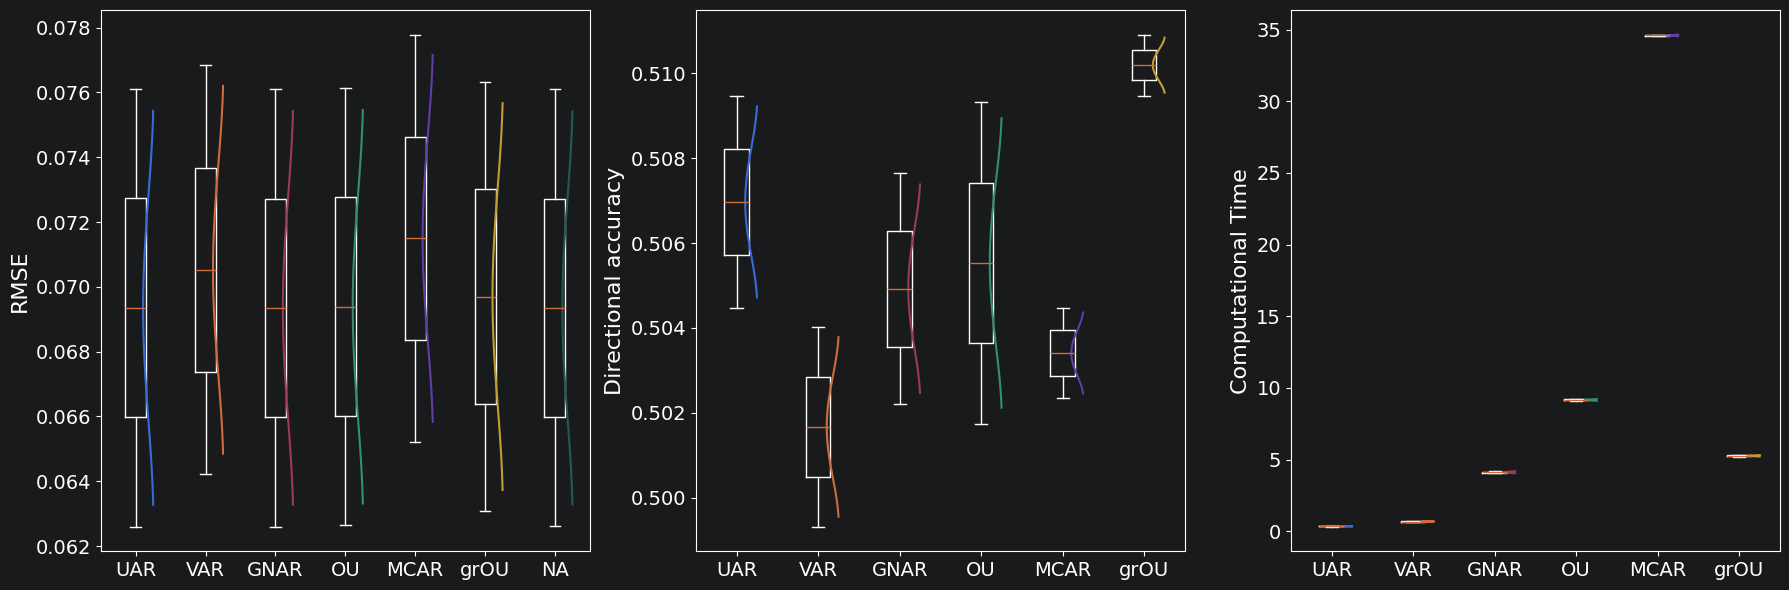

missing_1
                                UAR       VAR      GNAR        OU       MCAR  \
RMSE_mean                  0.069352  0.070526  0.069349  0.069385   0.071493   
RMSE_std                   0.006753  0.006307  0.006745  0.006744   0.006290   
Directional_accuracy_mean  0.506970  0.501667  0.504924  0.505530   0.503409   
Directional_accuracy_std   0.002500  0.002348  0.002727  0.003788   0.001061   
Computational_time_mean    0.347065  0.681575  4.117491  9.163125  34.589132   
Computational_time_std     0.024889  0.006759  0.085196  0.072686   0.058150   

                               grOU        NA  
RMSE_mean                  0.069699  0.069349  
RMSE_std                   0.006630  0.006741  
Directional_accuracy_mean  0.510189       NaN  
Directional_accuracy_std   0.000720       NaN  
Computational_time_mean    5.265300       NaN  
Computational_time_std     0.054624       NaN  


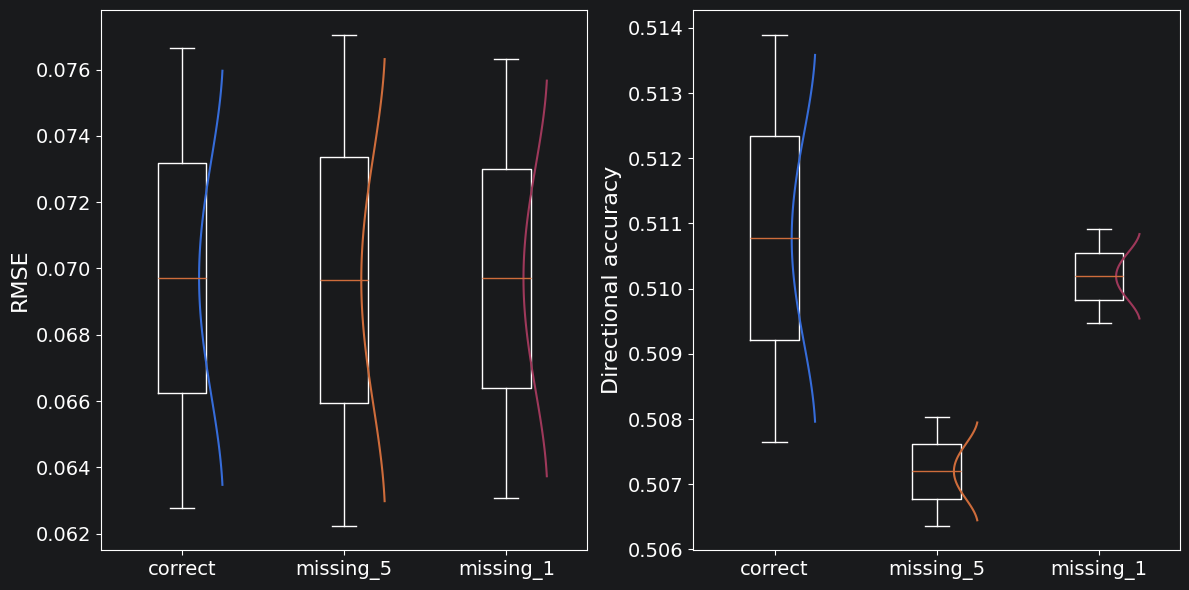

In [2]:
pred_robust(123, 0.15, 1.1, 20, 1, 3, 1)